In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df["target"] = y
df["class"] = [class_names[i] for i in y]

print("Shape of dataset:", X.shape)
print("\nClass distribution:")
print(df["class"].value_counts())

print("\nFeature statistics:")
print(df[feature_names].describe())

Shape of dataset: (150, 4)

Class distribution:
class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Feature statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


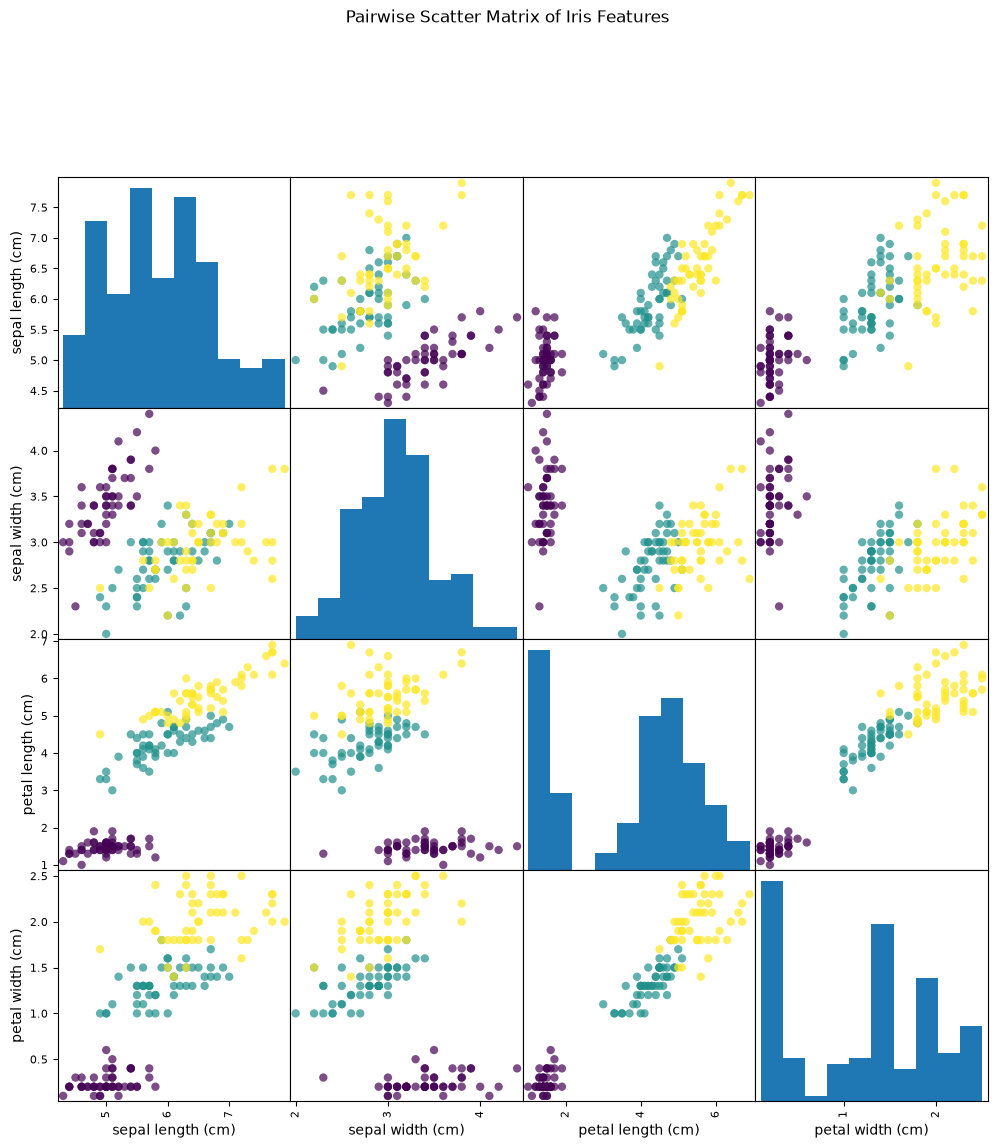

In [3]:
# Scatter matrix of all features
axes = pd.plotting.scatter_matrix(
    df[feature_names],
    figsize=(12, 12),
    diagonal="hist",
    c=y,
    marker="o",
    alpha=0.7
)

plt.suptitle("Pairwise Scatter Matrix of Iris Features", y=1.02)
plt.show()

In [4]:
# Functions to calculate entropy and Gini impurity
def entropy(y):
    values, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return -np.sum(probabilities * np.log2(probabilities))


def gini(y):
    values, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return 1 - np.sum(probabilities ** 2)


# Full dataset
full_entropy = entropy(y)
full_gini = gini(y)

# Split: petal length <= 2.45
left = y[X[:, 2] <= 2.45]
right = y[X[:, 2] > 2.45]

left_entropy = entropy(left)
right_entropy = entropy(right)

left_gini = gini(left)
right_gini = gini(right)

# Information Gain
weighted_entropy = (
    (len(left) / len(y)) * left_entropy
    + (len(right) / len(y)) * right_entropy
)

information_gain = full_entropy - weighted_entropy

print("Full dataset entropy:", full_entropy)
print("Full dataset Gini:", full_gini)

print("\nLeft subset (petal length <= 2.45)")
print("Number of samples:", len(left))
print("Entropy:", left_entropy)
print("Gini:", left_gini)

print("\nRight subset (petal length > 2.45)")
print("Number of samples:", len(right))
print("Entropy:", right_entropy)
print("Gini:", right_gini)

print("\nInformation Gain:", information_gain)

Full dataset entropy: 1.584962500721156
Full dataset Gini: 0.6666666666666667

Left subset (petal length <= 2.45)
Number of samples: 50
Entropy: -0.0
Gini: 0.0

Right subset (petal length > 2.45)
Number of samples: 100
Entropy: 1.0
Gini: 0.5

Information Gain: 0.9182958340544894


Decision Tree Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Decision Tree Text Representation:

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



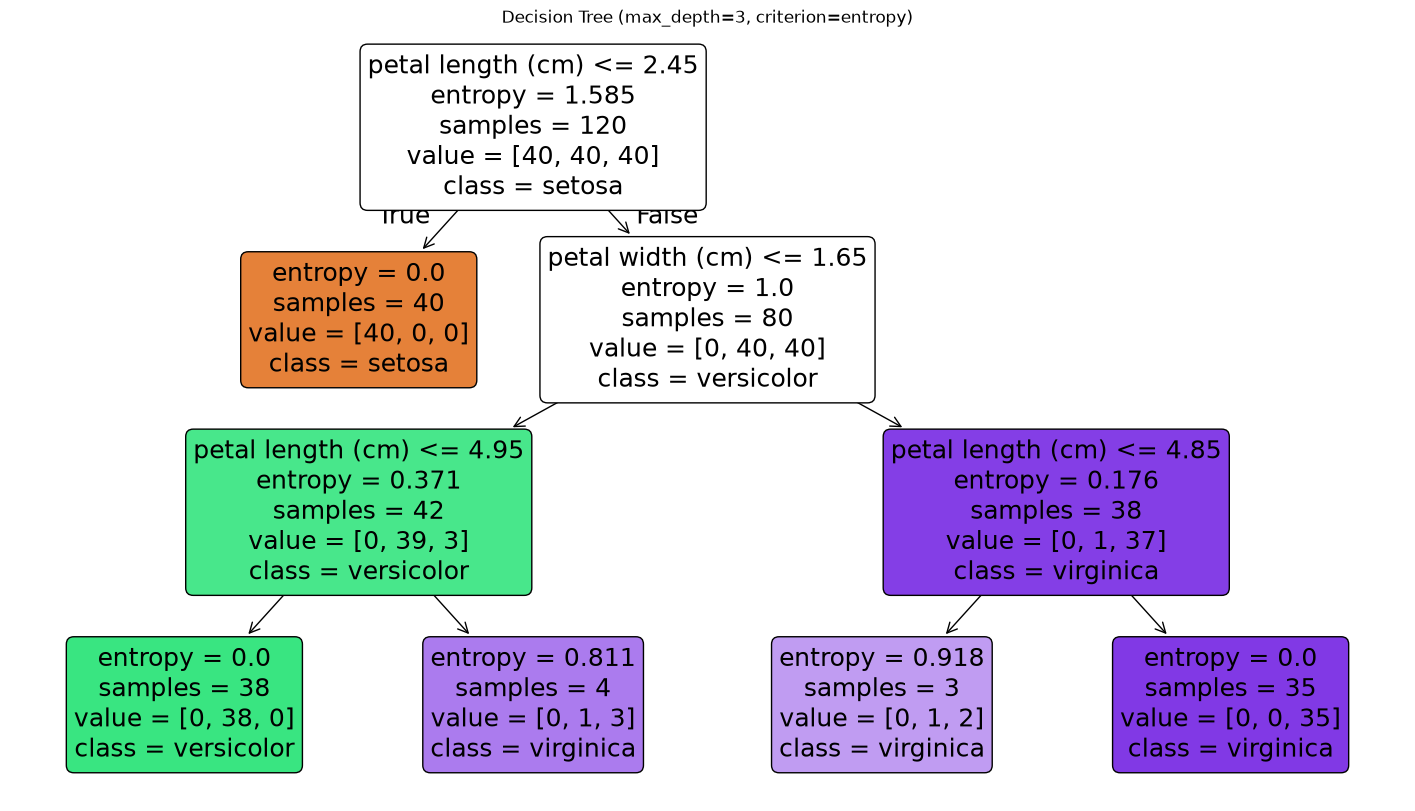

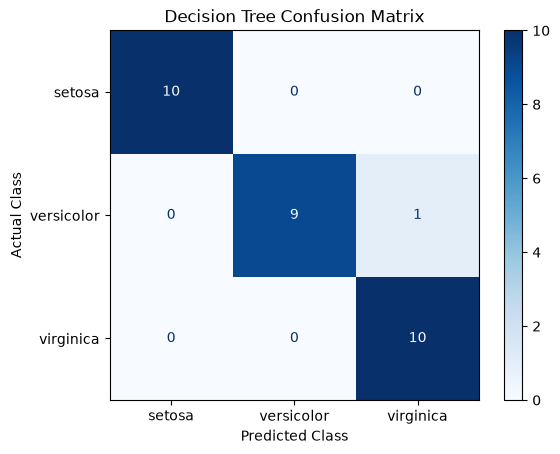

In [5]:
# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Decision Tree
dt = DecisionTreeClassifier(
    max_depth=3,
    criterion="entropy",
    random_state=42
)

dt.fit(X_train, y_train)

# Predictions
y_pred_dt = dt.predict(X_test)

print("Decision Tree Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=class_names
))

print("Decision Tree Text Representation:\n")
print(export_text(dt, feature_names=feature_names))

# Plot tree
plt.figure(figsize=(18, 10))

plot_tree(
    dt,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False
)

plt.title("Decision Tree (max_depth=3, criterion=entropy)")
plt.show()

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=class_names,
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

   Depth  Training Accuracy  Test Accuracy
0      1           0.666667       0.666667
1      2           0.966667       0.933333
2      3           0.983333       0.966667
3      4           0.991667       0.933333
4      5           1.000000       0.933333
5      6           1.000000       0.933333
6      7           1.000000       0.933333
7      8           1.000000       0.933333
8      9           1.000000       0.933333
9     10           1.000000       0.933333


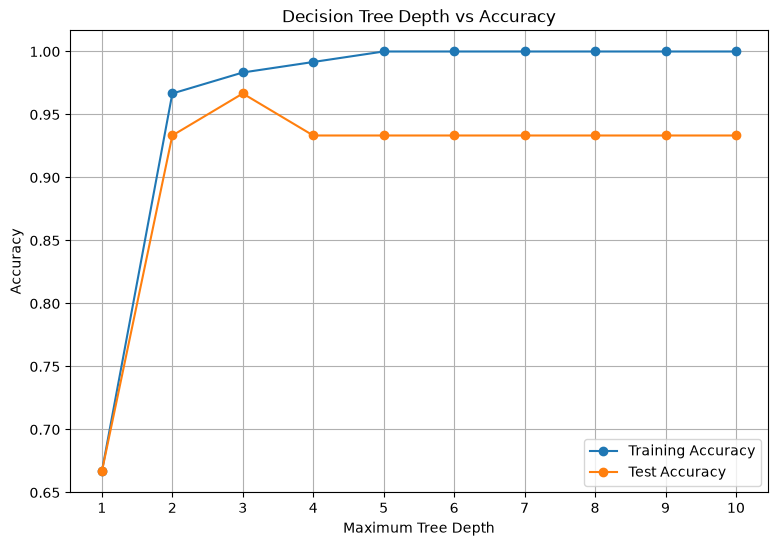

Best depth based on test accuracy: 3


In [6]:
depths = range(1, 11)

train_accuracies = []
test_accuracies = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        criterion="entropy",
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_accuracies.append(tree.score(X_train, y_train))
    test_accuracies.append(tree.score(X_test, y_test))


depth_results = pd.DataFrame({
    "Depth": depths,
    "Training Accuracy": train_accuracies,
    "Test Accuracy": test_accuracies
})

print(depth_results)

# Plot accuracy curves
plt.figure(figsize=(9, 6))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_accuracies,
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(test_accuracies)]

print("Best depth based on test accuracy:", best_depth)

Random Forest OOB Score: 0.9416666666666667

Random Forest Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



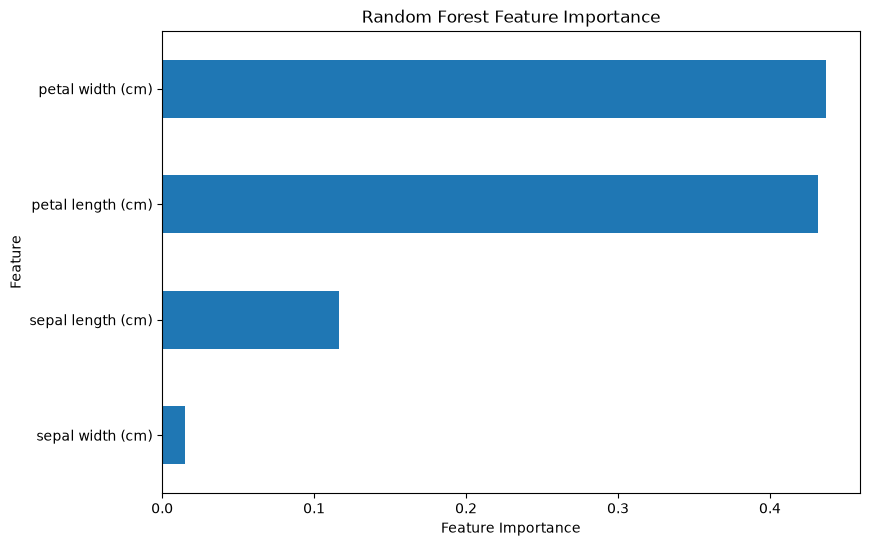

In [7]:
# Random Forest with default settings requested in assignment
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest OOB Score:", rf.oob_score_)

print("\nRandom Forest Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=class_names
))

# Feature importance
importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))

importance.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [8]:
# Parameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10, 15]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'n_estimators': 50}

Best Cross-Validation Accuracy:
0.95


Tuned Random Forest Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



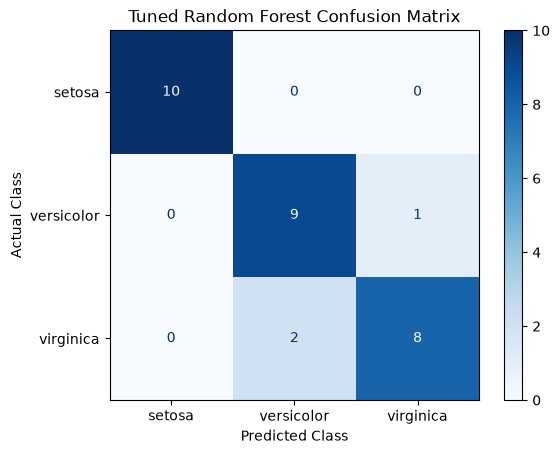

In [9]:
# Best Random Forest model
best_rf = grid_search.best_estimator_

# Test predictions
y_pred_tuned = best_rf.predict(X_test)

print("Tuned Random Forest Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=class_names
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=class_names,
    cmap="Blues"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [10]:
# Function to calculate model metrics
def get_metrics(y_true, y_pred):
    return {
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted"),
        "Recall": recall_score(y_true, y_pred, average="weighted"),
        "F1": f1_score(y_true, y_pred, average="weighted")
    }


dt_metrics = get_metrics(y_test, y_pred_dt)
rf_metrics = get_metrics(y_test, y_pred_rf)
tuned_rf_metrics = get_metrics(y_test, y_pred_tuned)

comparison = pd.DataFrame(
    [dt_metrics, rf_metrics, tuned_rf_metrics],
    index=[
        "Decision Tree (depth=3)",
        "Random Forest (default)",
        "Random Forest (tuned)"
    ]
)

print(comparison.round(4))

                         Test Accuracy  Precision  Recall      F1
Decision Tree (depth=3)         0.9667     0.9697  0.9667  0.9666
Random Forest (default)         0.9000     0.9024  0.9000  0.8997
Random Forest (tuned)           0.9000     0.9024  0.9000  0.8997


In [11]:
# Feature importance from tuned Random Forest
tuned_importance = pd.Series(
    best_rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Tuned Random Forest Feature Importance:")
print(tuned_importance)

print("\nMost important feature:", tuned_importance.index[0])
print("Best Random Forest parameters:", grid_search.best_params_)

# Compare model accuracies
print("\nModel Test Accuracies:")
for model, metrics in comparison.iterrows():
    print(f"{model}: {metrics['Test Accuracy']:.4f}")

Tuned Random Forest Feature Importance:
petal width (cm)     0.440371
petal length (cm)    0.430601
sepal length (cm)    0.114760
sepal width (cm)     0.014267
dtype: float64

Most important feature: petal width (cm)
Best Random Forest parameters: {'max_depth': None, 'n_estimators': 50}

Model Test Accuracies:
Decision Tree (depth=3): 0.9667
Random Forest (default): 0.9000
Random Forest (tuned): 0.9000


In [12]:
best_model = comparison["Test Accuracy"].idxmax()

print("FINAL CONCLUSION")
print("=" * 50)

print(f"Best performing model: {best_model}")
print(
    f"Best test accuracy: "
    f"{comparison.loc[best_model, 'Test Accuracy']:.4f}"
)

print("\nInterpretation:")
print("1. Petal length and petal width provide strong separation between Iris classes.")
print("2. Increasing tree depth improves training performance but can lead to overfitting.")
print("3. Random Forest reduces the variance of a single Decision Tree.")
print("4. OOB score provides an additional estimate of Random Forest generalisation.")
print("5. A Decision Tree is preferable when interpretability and simple visual explanation are more important than maximum accuracy.")
print("6. Random Forest is preferable when predictive performance and robustness are the main priorities.")

FINAL CONCLUSION
Best performing model: Decision Tree (depth=3)
Best test accuracy: 0.9667

Interpretation:
1. Petal length and petal width provide strong separation between Iris classes.
2. Increasing tree depth improves training performance but can lead to overfitting.
3. Random Forest reduces the variance of a single Decision Tree.
4. OOB score provides an additional estimate of Random Forest generalisation.
5. A Decision Tree is preferable when interpretability and simple visual explanation are more important than maximum accuracy.
6. Random Forest is preferable when predictive performance and robustness are the main priorities.
